<a href="https://colab.research.google.com/github/MuhammadAmaan178/Demand-Lens/blob/main/notebooks/DLens_05_DecisionTree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Exact path to your processed folder
path = "/content/drive/MyDrive/DemandLens/Data/"
OUT_PROCESSED = path + "processed/"

In [ ]:
# Load 7-Day Horizon Train & Validation Datasets
train_7  = pd.read_parquet(f"{OUT_PROCESSED}ca1_h7_train.parquet")
val_7    = pd.read_parquet(f"{OUT_PROCESSED}ca1_h7_val.parquet")

In [ ]:
#  Load 28-Day Horizon Train & Validation Datasets
train_28 = pd.read_parquet(f"{OUT_PROCESSED}ca1_h28_train.parquet")
val_28   = pd.read_parquet(f"{OUT_PROCESSED}ca1_h28_val.parquet")

In [ ]:
train_7.shape, val_7.shape

((4552041, 26), (85372, 26))

In [ ]:
train_28.shape, val_28.shape

((4424067, 26), (85359, 26))

In [ ]:
pd.set_option("display.max_columns", None)

In [ ]:
train_7.head()

,item_id,store_id,date,sales,lag_7,rolling_mean_7,wday,month,year,is_weekend,snap,has_event,sell_price,price_change,ev_Cultural,ev_National,ev_Religious,ev_Sporting,ev_None,dept_FOODS_1,dept_FOODS_2,dept_FOODS_3,dept_HOBBIES_1,dept_HOBBIES_2,dept_HOUSEHOLD_1,dept_HOUSEHOLD_2
0,FOODS_1_001,CA_1,2011-02-09,0,4.0,1.600000,5,2,2011,0,1,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
1,FOODS_1_001,CA_1,2011-02-10,3,2.0,1.666667,6,2,2011,0,1,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
2,FOODS_1_001,CA_1,2011-02-11,1,0.0,1.428571,7,2,2011,0,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
3,FOODS_1_001,CA_1,2011-02-12,3,2.0,1.285714,1,2,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
4,FOODS_1_001,CA_1,2011-02-13,0,0.0,1.285714,2,2,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0


In [ ]:
train_28.head()

,item_id,store_id,date,sales,lag_28,rolling_mean_28,wday,month,year,is_weekend,snap,has_event,sell_price,price_change,ev_Cultural,ev_National,ev_Religious,ev_Sporting,ev_None,dept_FOODS_1,dept_FOODS_2,dept_FOODS_3,dept_HOBBIES_1,dept_HOBBIES_2,dept_HOUSEHOLD_1,dept_HOUSEHOLD_2
0,FOODS_1_001,CA_1,2011-03-23,1,2.0,1.269231,5,3,2011,0,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
1,FOODS_1_001,CA_1,2011-03-24,0,2.0,1.296296,6,3,2011,0,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
2,FOODS_1_001,CA_1,2011-03-25,1,4.0,1.392857,7,3,2011,0,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
3,FOODS_1_001,CA_1,2011-03-26,2,2.0,1.357143,1,3,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
4,FOODS_1_001,CA_1,2011-03-27,2,2.0,1.428571,2,3,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0


In [ ]:
drop_cols = ["item_id", "store_id", "date", "sales"]

In [ ]:
# 7-Day Horizon
X_train_7 = train_7.drop(columns=drop_cols)
y_train_7 = train_7["sales"]
X_val_7   = val_7.drop(columns=drop_cols)
y_val_7   = val_7["sales"]

In [ ]:
# 28-Day Horizon
X_train_28 = train_28.drop(columns=drop_cols)
y_train_28 = train_28["sales"]
X_val_28   = val_28.drop(columns=drop_cols)
y_val_28   = val_28["sales"]

In [ ]:
X_train_7.shape, y_train_7.shape, X_val_7.shape, y_val_7.shape

((4552041, 22), (4552041,), (85372, 22), (85372,))

In [ ]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

In [ ]:
# Evaluation function (identical to Ridge Regression for a 100% fair comparison)
def evaluate_forecast(y_true, y_pred):
    y_pred_clipped = np.clip(y_pred, 0, None)
    wape = np.sum(np.abs(y_true - y_pred_clipped)) / np.sum(np.abs(y_true)) * 100
    mae  = mean_absolute_error(y_true, y_pred_clipped)
    rmse = root_mean_squared_error(y_true, y_pred_clipped)
    return {"WAPE (%)": round(wape, 2), "MAE": round(mae, 4), "RMSE": round(rmse, 4)}

In [ ]:
from sklearn.tree import DecisionTreeRegressor

In [ ]:
depths = [4, 6, 8, 10, 12, 15, 20]

results_7  = []
results_28 = []

In [ ]:
for d in depths:
    # 7-Day Decision Tree
    dt7 = DecisionTreeRegressor(max_depth=d, min_samples_leaf=50, random_state=42)
    dt7.fit(X_train_7, y_train_7)
    val_metrics_7 = evaluate_forecast(y_val_7, dt7.predict(X_val_7))
    train_wape_7  = evaluate_forecast(y_train_7, dt7.predict(X_train_7))["WAPE (%)"]
    results_7.append({"max_depth": d, "Train WAPE (%)": train_wape_7, **val_metrics_7})

    # 28-Day Decision Tree
    dt28 = DecisionTreeRegressor(max_depth=d, min_samples_leaf=50, random_state=42)
    dt28.fit(X_train_28, y_train_28)
    val_metrics_28 = evaluate_forecast(y_val_28, dt28.predict(X_val_28))
    train_wape_28  = evaluate_forecast(y_train_28, dt28.predict(X_train_28))["WAPE (%)"]
    results_28.append({"max_depth": d, "Train WAPE (%)": train_wape_28, **val_metrics_28})

In [ ]:
df_dt_7  = pd.DataFrame(results_7).sort_values("WAPE (%)")
df_dt_28 = pd.DataFrame(results_28).sort_values("WAPE (%)")

In [ ]:
print("7-Day Decision Tree Tuning (Sorted by Val WAPE)")
print(df_dt_7.to_string(index=False))

7-Day Decision Tree Tuning (Sorted by Val WAPE)
 max_depth  Train WAPE (%)  WAPE (%)    MAE   RMSE
        15           72.49     75.17 1.1267 2.1924
        12           73.14     75.20 1.1271 2.1868
        10           73.63     75.30 1.1286 2.1906
        20           71.47     75.48 1.1313 2.2056
         8           74.31     75.71 1.1347 2.1901
         6           75.15     76.19 1.1419 2.2031
         4           77.42     78.17 1.1717 2.2480


In [ ]:
print("28-Day Decision Tree Tuning (Sorted by Val WAPE)")
print(df_dt_28.to_string(index=False))

28-Day Decision Tree Tuning (Sorted by Val WAPE)
 max_depth  Train WAPE (%)  WAPE (%)    MAE   RMSE
        10           77.67     76.37 1.1447 2.2262
         8           78.33     76.53 1.1470 2.2290
        12           77.05     76.61 1.1482 2.2452
         6           78.90     76.90 1.1526 2.2442
        15           76.27     77.06 1.1550 2.2670
        20           75.01     77.84 1.1666 2.2863
         4           81.04     79.11 1.1857 2.2927


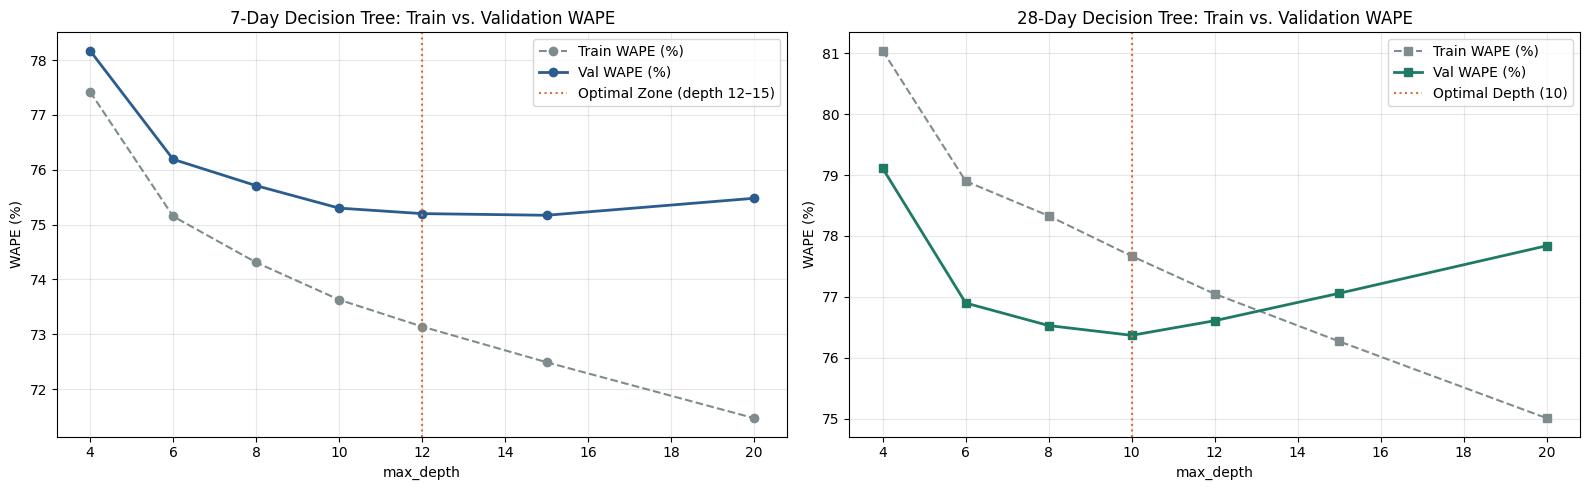

In [ ]:
# 1. Plot Train vs. Val WAPE across max_depth
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

d7_s  = df_dt_7.sort_values("max_depth")
d28_s = df_dt_28.sort_values("max_depth")

axes[0].plot(d7_s["max_depth"], d7_s["Train WAPE (%)"], marker="o", linestyle="--", label="Train WAPE (%)", color="#7f8c8d")
axes[0].plot(d7_s["max_depth"], d7_s["WAPE (%)"], marker="o", linewidth=2, label="Val WAPE (%)", color="#2b5c8f")
axes[0].axvline(12, color="#e06c38", linestyle=":", label="Optimal Zone (depth 12–15)")
axes[0].set_title("7-Day Decision Tree: Train vs. Validation WAPE")
axes[0].set_xlabel("max_depth")
axes[0].set_ylabel("WAPE (%)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(d28_s["max_depth"], d28_s["Train WAPE (%)"], marker="s", linestyle="--", label="Train WAPE (%)", color="#7f8c8d")
axes[1].plot(d28_s["max_depth"], d28_s["WAPE (%)"], marker="s", linewidth=2, label="Val WAPE (%)", color="#1f7a63")
axes[1].axvline(10, color="#e06c38", linestyle=":", label="Optimal Depth (10)")
axes[1].set_title("28-Day Decision Tree: Train vs. Validation WAPE")
axes[1].set_xlabel("max_depth")
axes[1].set_ylabel("WAPE (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

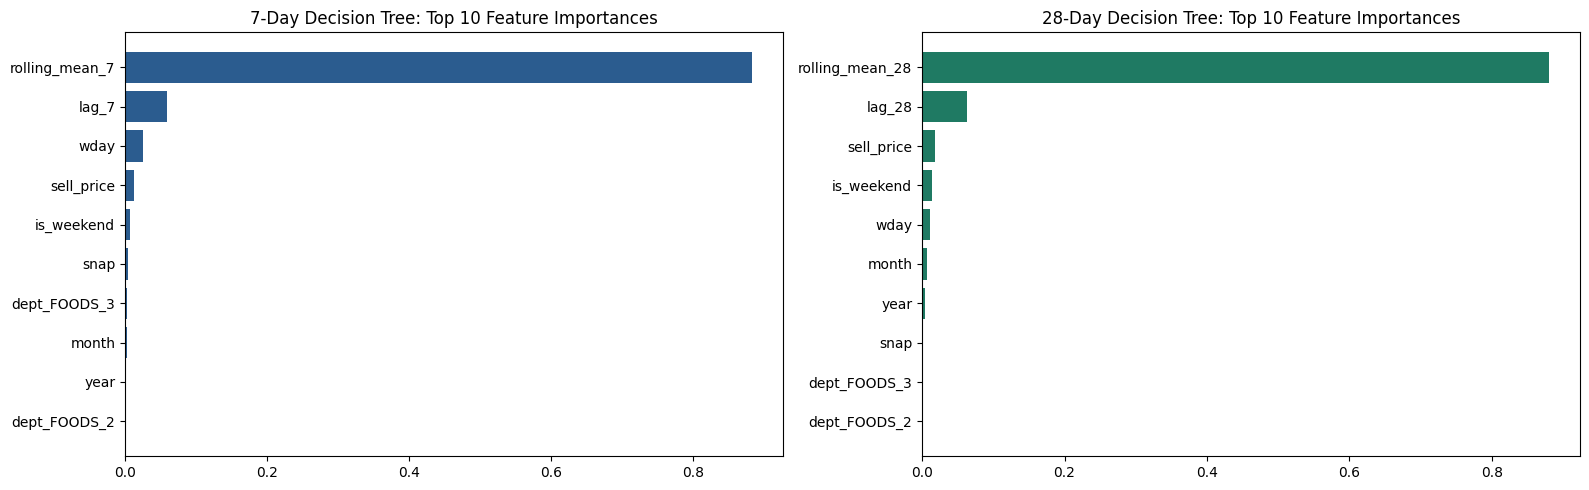

In [ ]:
# 2. Fit winning models (depth=12 or 15 for 7-Day, depth=10 for 28-Day) & plot Top 10 Feature Importances
best_dt_7  = DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=42).fit(X_train_7, y_train_7)
best_dt_28 = DecisionTreeRegressor(max_depth=10, min_samples_leaf=50, random_state=42).fit(X_train_28, y_train_28)

imp_7  = pd.DataFrame({"Feature": X_train_7.columns, "Importance": best_dt_7.feature_importances_}).sort_values("Importance").tail(10)
imp_28 = pd.DataFrame({"Feature": X_train_28.columns, "Importance": best_dt_28.feature_importances_}).sort_values("Importance").tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].barh(imp_7["Feature"], imp_7["Importance"], color="#2b5c8f")
axes[0].set_title("7-Day Decision Tree: Top 10 Feature Importances")

axes[1].barh(imp_28["Feature"], imp_28["Importance"], color="#1f7a63")
axes[1].set_title("28-Day Decision Tree: Top 10 Feature Importances")

plt.tight_layout()
plt.show()

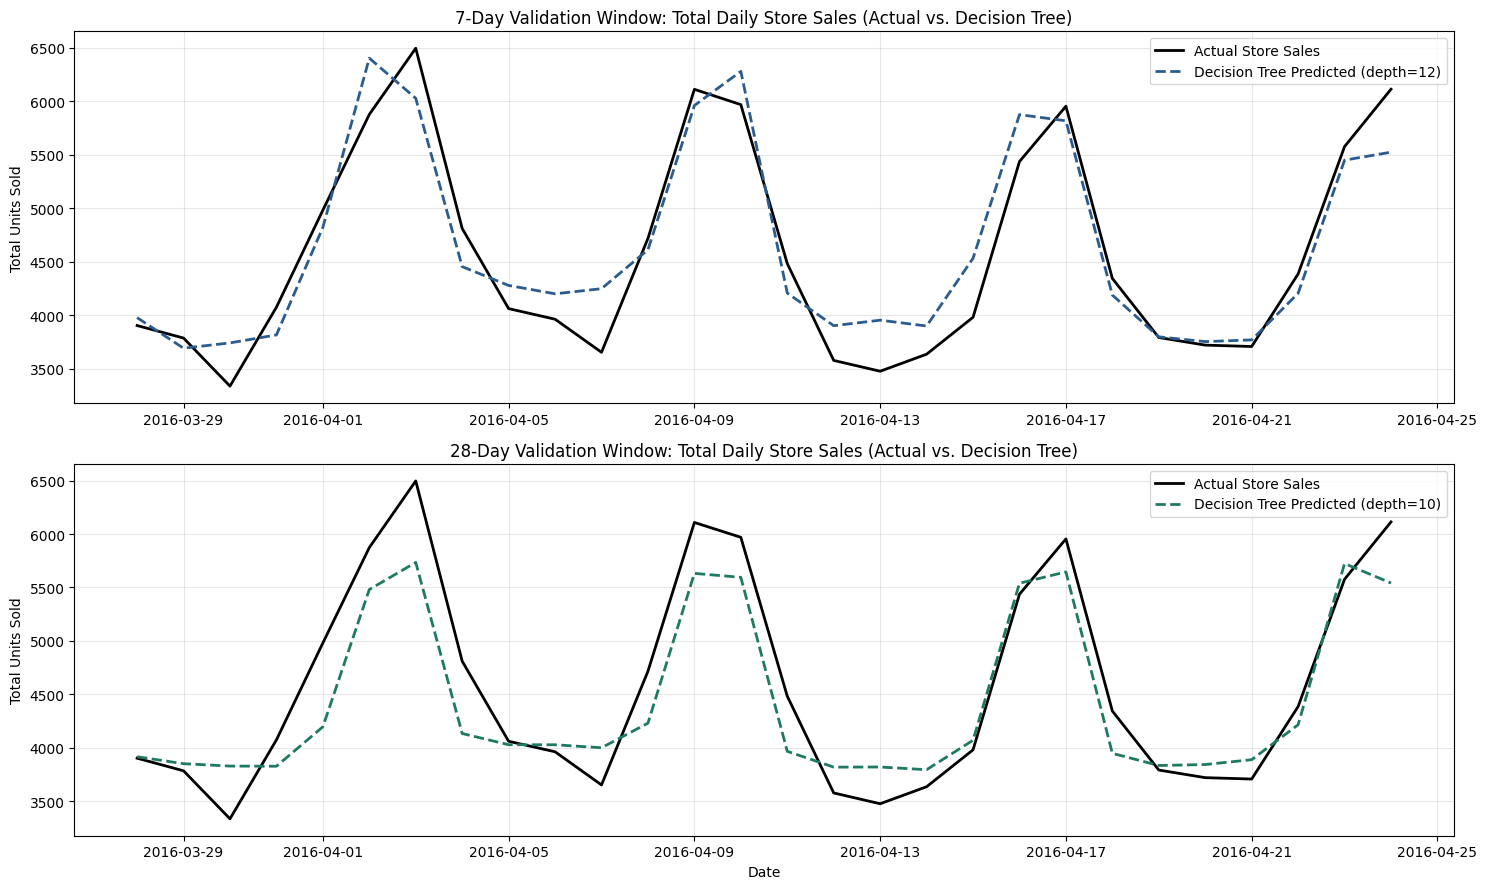

In [ ]:
# 1. Prepare 7-Day Daily Aggregated Actual vs. Predicted
val_plot_7 = val_7[["date", "sales"]].copy()
val_plot_7["predicted"] = np.clip(best_dt_7.predict(X_val_7), 0, None)
daily_agg_7 = val_plot_7.groupby("date")[["sales", "predicted"]].sum().reset_index()

# 2. Prepare 28-Day Daily Aggregated Actual vs. Predicted
val_plot_28 = val_28[["date", "sales"]].copy()
val_plot_28["predicted"] = np.clip(best_dt_28.predict(X_val_28), 0, None)
daily_agg_28 = val_plot_28.groupby("date")[["sales", "predicted"]].sum().reset_index()

# 3. Plot Side-by-Side Comparison
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=False)

# --- 7-Day Plot ---
axes[0].plot(daily_agg_7["date"], daily_agg_7["sales"], label="Actual Store Sales", color="black", linewidth=2)
axes[0].plot(daily_agg_7["date"], daily_agg_7["predicted"], label="Decision Tree Predicted (depth=12)", color="#2b5c8f", linestyle="--", linewidth=2)
axes[0].set_title("7-Day Validation Window: Total Daily Store Sales (Actual vs. Decision Tree)")
axes[0].set_ylabel("Total Units Sold")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# --- 28-Day Plot ---
axes[1].plot(daily_agg_28["date"], daily_agg_28["sales"], label="Actual Store Sales", color="black", linewidth=2)
axes[1].plot(daily_agg_28["date"], daily_agg_28["predicted"], label="Decision Tree Predicted (depth=10)", color="#1f7a63", linestyle="--", linewidth=2)
axes[1].set_title("28-Day Validation Window: Total Daily Store Sales (Actual vs. Decision Tree)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Total Units Sold")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()